# Проект по программированию

> #### ЛФИ 1 курс,  группа Б02-409, Галанин Михаил, Мамонов Вениамин, Нурсагатов Маргулан

В данном проекте исследуется зависимость успеваемости студентов (здесь и далее - **Performance Index**), в зависимости от таких показателей, как количество выделенных на учёбу часов в день (**Hours Studied**), предыдущих оценок (**Previous Scores**), наличия взятых факультативов (**Extracurricular Activities**), количество часов на сон в день (**Sleep Hours**), а также количества выученных билетов (**Sample Question Papers Practiced**)

>Для начала импортируем все нужные библиотеки и функции, а также файл с данными:

In [22]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [17]:
df  = pd.read_csv('Student_Performance.csv')

df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0



Заметим, что у **Extracurricular Activities** очень неудобный тип данных. Преобразуем _"YES"_ в 1 и _''NO''_ в 0

In [19]:
encoder = LabelEncoder()
for column in df.select_dtypes(["object"]):
    df[column] = encoder.fit_transform(df[column])
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


> #### Для этих данных построим распределение признаков:

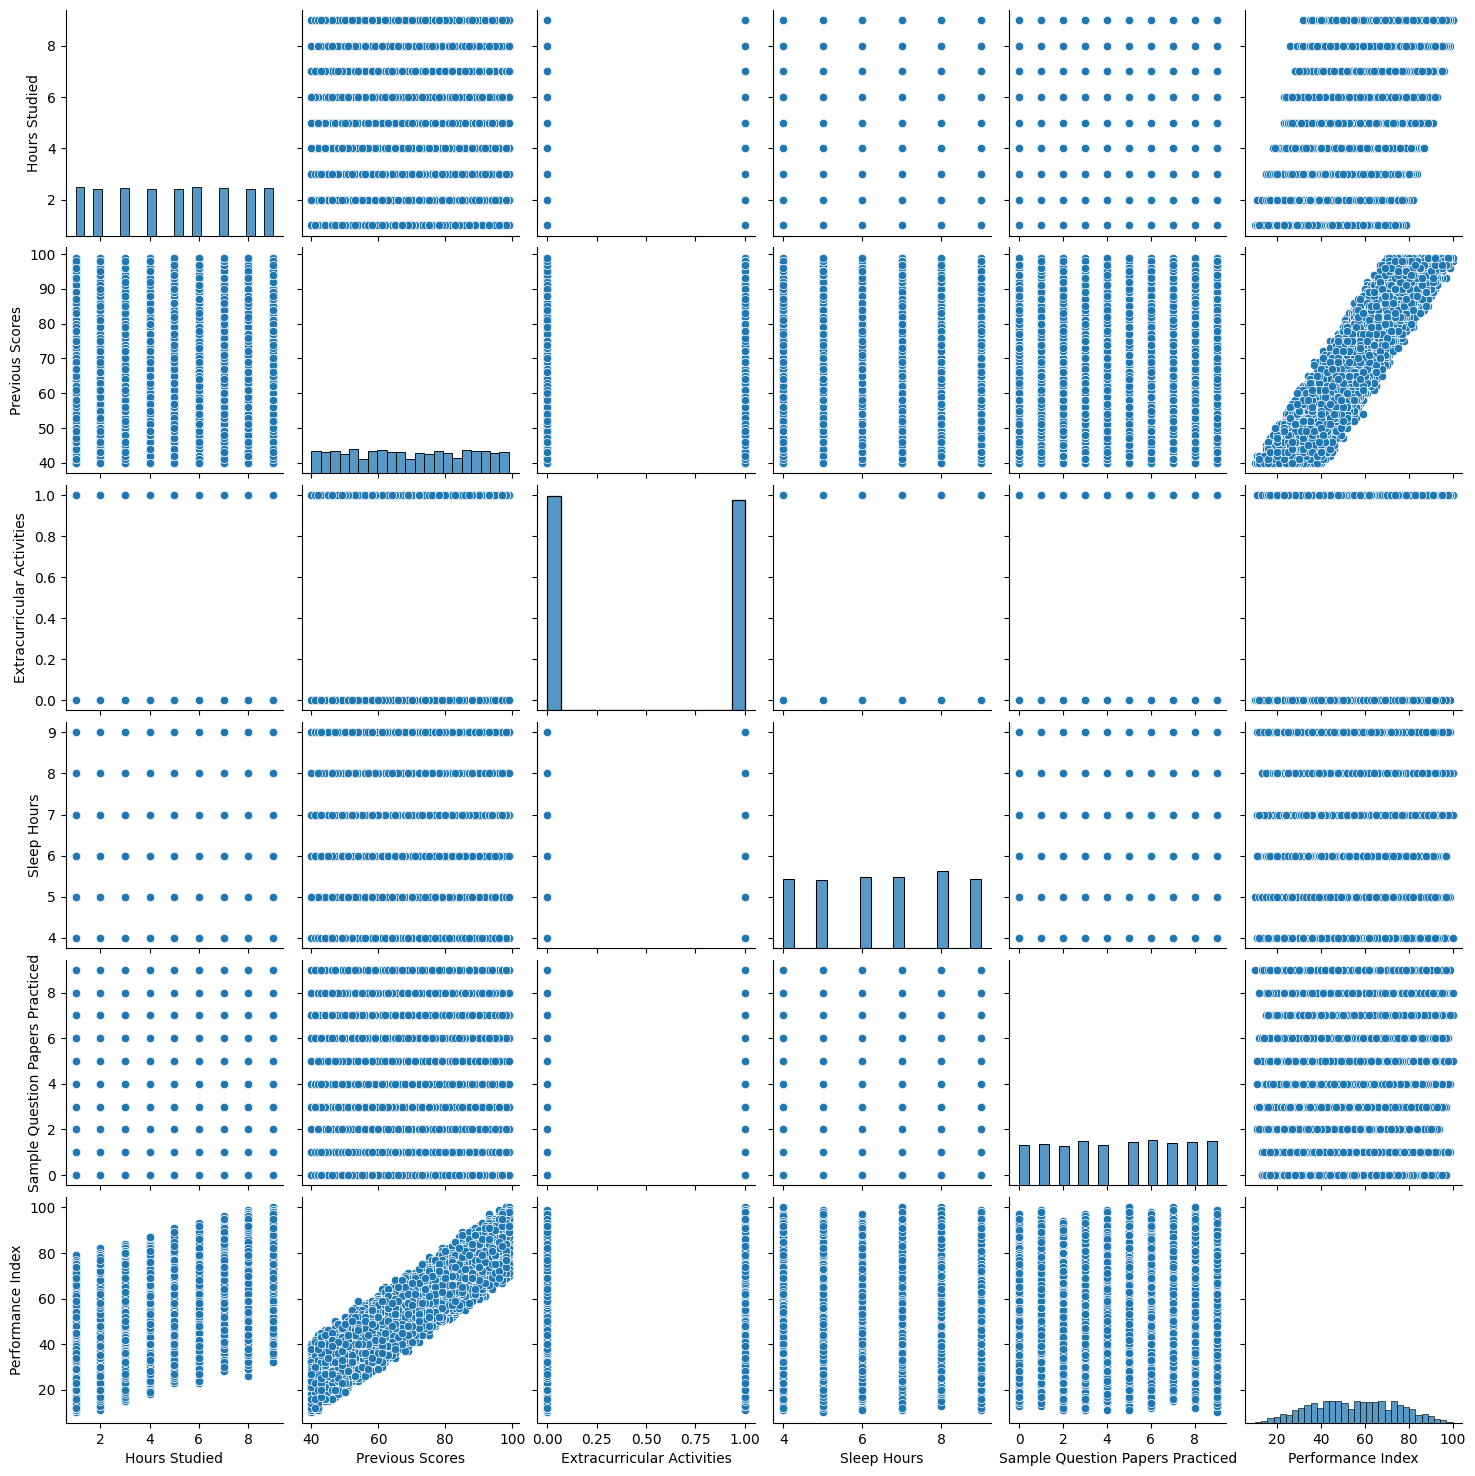

In [40]:
sns.pairplot(df);

> #### и корреляционную матрицу:

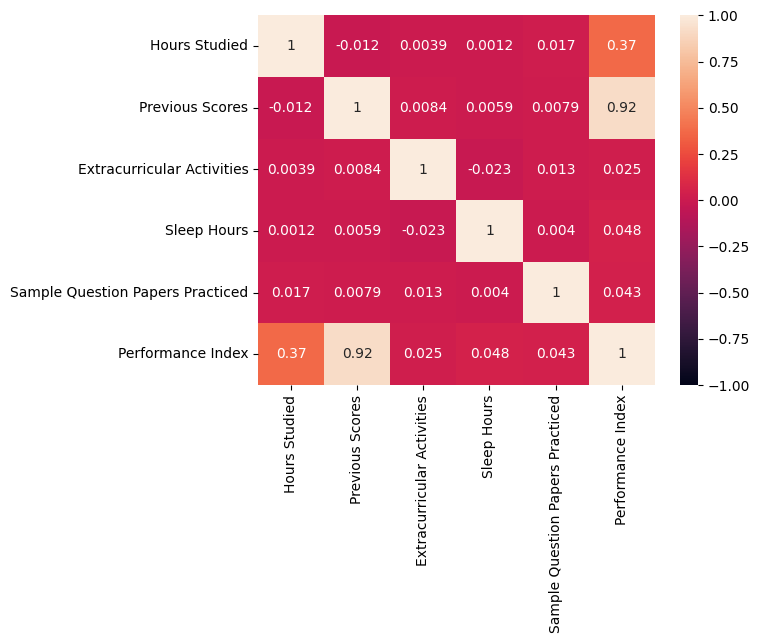

In [45]:
correlation_df = df.corr()
plt.figure()
sns.heatmap(correlation_df, vmin=-1, vmax=1, annot=True);

Отсюда видно прямую зависимость **Performance Index** от **Hours Studied** и **Previous Scores**

> причём как видно из корелляционной матрицы, зависимость от _предыдущих оценок_ (Previous Scores) куда больше, чем зависимость от _количества выделенных на учёбу часов в день_ (Hours Studied)

Также видно, что **Performance Index** не зависит от **Extracurriculcar Activities**, **Sleep Hours** и **Sample Question Papers Practiced**

>Более того распределение людей по оценкам представляет собой нормальное распределение.
>Из этого можно сделать вывод, что на величину успеваемости студентов (**Performance Index**) влияют слабо взаимозависимые величины, каждая из которых вносит малый вклад относительно общего результата

> #### также посмотрим совместное распределение признаков:

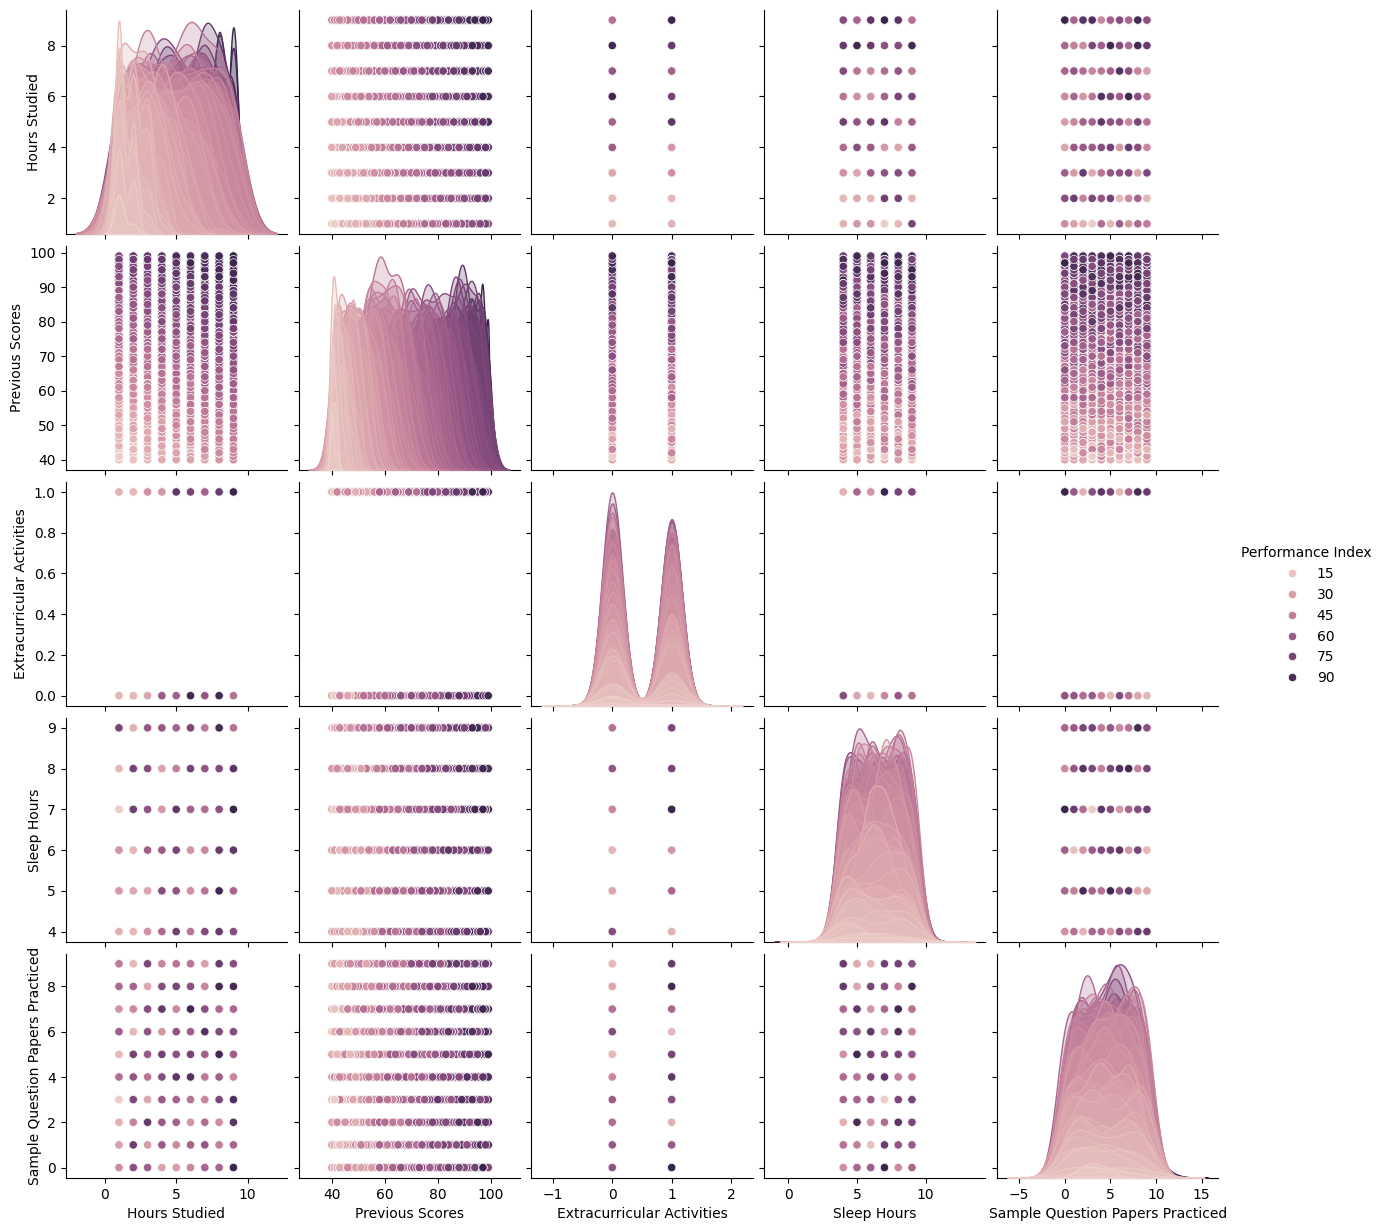

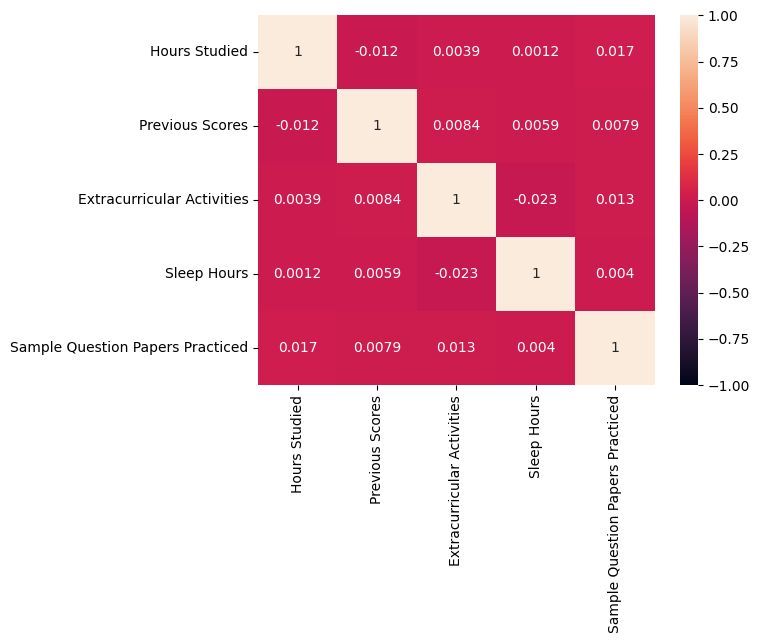

In [66]:
sns.pairplot(df, hue="Performance Index")

plt.figure()
correlation_df = df[feature_names].corr()
sns.heatmap(correlation_df, vmin=-1, vmax=1, annot=True);

То есть выбранные показатели не зависят друг от друга (коэффициент корреляции близок к нулю везде)

Таким образом, нынешняя успеваемость студента в основном зависит от прошлых оценок рассматриваемого студента (то есть от успеваемости в прошлом — **Previous Scores**), и немногозависит от усердной работы (то есть от количества часов, затрачиваемых на учёбу — **Hours Studied**).
Отсюда мы видим, что несмотря на то, что жизнь тлен и ничего нельзя изменить, иногда всё же можно, если очень стараться

Попроубем реализовать модель используя различные подходы:

#### **Дерево решений**

In [58]:
feature_names = df.columns[:-1]
target_name = df.columns[-1]
from sklearn.model_selection import train_test_split
from sklearn import tree

model_tree = tree.DecisionTreeClassifier()

X = df[feature_names].to_numpy()
y = df[target_name].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

model_tree.fit(X_train, y_train)

from sklearn.metrics import accuracy_score, confusion_matrix

print(accuracy_score(y_true=y_test, y_pred=model_tree.predict(X_test)))

0.133


Точность модели дерева решений — 13.6%, что не особо результативно

#### **Метод пяти ближайших соседей**

In [61]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
model_knn.fit(X=X_train, y=y_train)
y_pred = model_knn.predict(X_test)

from sklearn.metrics import accuracy_score, confusion_matrix

knn_accuracy = accuracy_score(y_true=y_test, y_pred=y_pred)
knn_confussion_matrix = confusion_matrix(y_true=y_test, y_pred=y_pred)

print(f"Accuracy of kNN: {knn_accuracy}")

Accuracy of kNN: 0.1035


Точность модели пяти ближайших соседей — 10.35%, что ещё менее результативно